In [1]:
# 1. Imports and environment configuration

import json
import warnings
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from time import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Project paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data"
SPLIT_DIR = DATA_DIR / "splits"
EXTERNAL_DIR = DATA_DIR / "external_evaluation"

MODEL_DIR = PROJECT_ROOT / "models" / "traditional_binary"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "external_evaluation_traditional_ml"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Environment configured successfully.")
print("Project root:", PROJECT_ROOT)
print("Training data directory:", SPLIT_DIR)
print("External evaluation directory:", EXTERNAL_DIR)
print("Model output directory:", MODEL_DIR)
print("Prediction output directory:", OUTPUT_DIR)

Environment configured successfully.
Project root: d:\Programs and Codes\financial-scam-analysis
Training data directory: d:\Programs and Codes\financial-scam-analysis\data\splits
External evaluation directory: d:\Programs and Codes\financial-scam-analysis\data\external_evaluation
Model output directory: d:\Programs and Codes\financial-scam-analysis\models\traditional_binary
Prediction output directory: d:\Programs and Codes\financial-scam-analysis\outputs\external_evaluation_traditional_ml


In [2]:
# 2. Load original training and validation splits

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")

required_columns = {"normalized_text", "label"}

for name, df in [("Training", train_df), ("Validation", val_df)]:
    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(f"{name} data is missing columns: {missing}")

    if df["normalized_text"].isna().any():
        raise ValueError(f"{name} data contains missing text values.")

    if df["label"].isna().any():
        raise ValueError(f"{name} data contains missing labels.")

    print(f"\n{name} set")
    print("Rows:", len(df))
    print("Class distribution:")
    print(df["label"].value_counts().sort_index())
    print("Text columns:", df["normalized_text"].dtype)

print("\nTraining and validation data loaded successfully.")


Training set
Rows: 60957
Class distribution:
label
0    49866
1    11091
Name: count, dtype: int64
Text columns: str

Validation set
Rows: 7618
Class distribution:
label
0    6233
1    1385
Name: count, dtype: int64
Text columns: str

Training and validation data loaded successfully.


In [3]:
# 3. Reconstruct the original TF-IDF representation

X_train_text = train_df["normalized_text"].astype(str)
X_val_text = val_df["normalized_text"].astype(str)

y_train = train_df["label"].astype(int)
y_val = val_df["label"].astype(int)

vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 1),
    min_df=1,
    max_df=1.0,
    dtype=np.float32
)

start_time = time()

X_train = vectorizer.fit_transform(X_train_text)
X_val = vectorizer.transform(X_val_text)

elapsed = time() - start_time

print("TF-IDF vectorization completed.")
print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))
print(f"Elapsed time: {elapsed:.2f} seconds")
print("Training matrix dtype:", X_train.dtype)
print("Validation matrix dtype:", X_val.dtype)

TF-IDF vectorization completed.
Training matrix: (60957, 115436)
Validation matrix: (7618, 115436)
Vocabulary size: 115436
Elapsed time: 8.38 seconds
Training matrix dtype: float32
Validation matrix dtype: float32


In [4]:
# 4. Train Logistic Regression baseline

lr_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42,
    solver="liblinear"
)

start_time = time()
lr_model.fit(X_train, y_train)
lr_train_time = time() - start_time

lr_val_pred = lr_model.predict(X_val)
lr_val_prob = lr_model.predict_proba(X_val)[:, 1]

print("Logistic Regression training completed.")
print(f"Training time: {lr_train_time:.2f} seconds")
print("\nValidation results:")
print(f"Accuracy:  {accuracy_score(y_val, lr_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, lr_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, lr_val_pred):.4f}")
print(f"Scam F1:   {f1_score(y_val, lr_val_pred):.4f}")
print(f"Macro F1:  {f1_score(y_val, lr_val_pred, average='macro'):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, lr_val_prob):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, lr_val_pred))

Logistic Regression training completed.
Training time: 1.63 seconds

Validation results:
Accuracy:  0.9941
Precision: 0.9725
Recall:    0.9957
Scam F1:   0.9839
Macro F1:  0.9902
PR-AUC:    0.9991

Confusion matrix:
[[6194   39]
 [   6 1379]]


In [5]:
# 5. Train Multinomial Naive Bayes baseline

nb_model = MultinomialNB(alpha=1.0)

start_time = time()
nb_model.fit(X_train, y_train)
nb_train_time = time() - start_time

nb_val_pred = nb_model.predict(X_val)
nb_val_prob = nb_model.predict_proba(X_val)[:, 1]

print("Multinomial Naive Bayes training completed.")
print(f"Training time: {nb_train_time:.2f} seconds")

print("\nValidation results:")
print(f"Accuracy:  {accuracy_score(y_val, nb_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, nb_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, nb_val_pred):.4f}")
print(f"Scam F1:   {f1_score(y_val, nb_val_pred):.4f}")
print(f"Macro F1:  {f1_score(y_val, nb_val_pred, average='macro'):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, nb_val_prob):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, nb_val_pred))

Multinomial Naive Bayes training completed.
Training time: 0.21 seconds

Validation results:
Accuracy:  0.9693
Precision: 0.9991
Recall:    0.8318
Scam F1:   0.9078
Macro F1:  0.9447
PR-AUC:    0.9936

Confusion matrix:
[[6232    1]
 [ 233 1152]]


In [6]:
# 6. Train Linear Support Vector Machine

svm_model = LinearSVC(
    C=1.0,
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

start_time = time()
svm_model.fit(X_train, y_train)
svm_train_time = time() - start_time

svm_val_pred = svm_model.predict(X_val)
svm_val_scores = svm_model.decision_function(X_val)

print("Linear SVM training completed.")
print(f"Training time: {svm_train_time:.2f} seconds")

print("\nValidation results:")
print(f"Accuracy:  {accuracy_score(y_val, svm_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, svm_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, svm_val_pred):.4f}")
print(f"Scam F1:   {f1_score(y_val, svm_val_pred):.4f}")
print(f"Macro F1:  {f1_score(y_val, svm_val_pred, average='macro'):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, svm_val_scores):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_val, svm_val_pred))

print("\nConvergence status:")
print("Iterations:", svm_model.n_iter_)

Linear SVM training completed.
Training time: 0.70 seconds

Validation results:
Accuracy:  0.9970
Precision: 0.9899
Recall:    0.9935
Scam F1:   0.9917
Macro F1:  0.9949
PR-AUC:    0.9997

Confusion matrix:
[[6219   14]
 [   9 1376]]

Convergence status:
Iterations: 79


In [7]:
# 7. Consolidated validation comparison

validation_results = []

models_and_predictions = [
    ("Logistic Regression", lr_val_pred, lr_val_prob),
    ("Multinomial Naive Bayes", nb_val_pred, nb_val_prob),
    ("Linear SVM", svm_val_pred, svm_val_scores)
]

for model_name, predictions, scores in models_and_predictions:
    validation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "Scam F1": f1_score(y_val, predictions),
        "Macro F1": f1_score(y_val, predictions, average="macro"),
        "PR-AUC": average_precision_score(y_val, scores)
    })

validation_results_df = pd.DataFrame(validation_results)

display(
    validation_results_df.style.format({
        col: "{:.4f}" for col in validation_results_df.columns
        if col != "Model"
    })
)

,Model,Accuracy,Precision,Recall,Scam F1,Macro F1,PR-AUC
0,Logistic Regression,0.9941,0.9725,0.9957,0.9839,0.9902,0.9991
1,Multinomial Naive Bayes,0.9693,0.9991,0.8318,0.9078,0.9447,0.9936
2,Linear SVM,0.9970,0.9899,0.9935,0.9917,0.9949,0.9997


In [8]:
# 8. Save reconstructed traditional ML artifacts

artifacts = {
    "tfidf_vectorizer.joblib": vectorizer,
    "logistic_regression.joblib": lr_model,
    "multinomial_nb.joblib": nb_model,
    "linear_svm.joblib": svm_model
}

for filename, artifact in artifacts.items():
    artifact_path = MODEL_DIR / filename
    joblib.dump(artifact, artifact_path)
    print(f"Saved: {artifact_path.name} ({artifact_path.stat().st_size / (1024**2):.2f} MB)")

# Save experiment configuration and validation metrics
metadata = {
    "experiment": "Traditional ML External Generalization Evaluation",
    "random_state": RANDOM_STATE,
    "vectorizer": {
        "analyzer": "word",
        "ngram_range": [1, 1],
        "min_df": 1,
        "max_df": 1.0,
        "dtype": "float32",
        "vocabulary_size": len(vectorizer.vocabulary_)
    },
    "training_samples": len(train_df),
    "validation_samples": len(val_df),
    "models": {
        "logistic_regression": {
            "class_weight": "balanced",
            "max_iter": 1000,
            "solver": "liblinear"
        },
        "multinomial_nb": {
            "alpha": 1.0
        },
        "linear_svm": {
            "C": 1.0,
            "class_weight": "balanced",
            "max_iter": 2000
        }
    },
    "validation_metrics": validation_results_df.to_dict(orient="records")
}

metadata_path = MODEL_DIR / "experiment_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("\nExperiment metadata saved.")
print("Artifact directory:", MODEL_DIR)

Saved: tfidf_vectorizer.joblib (2.06 MB)
Saved: logistic_regression.joblib (0.88 MB)
Saved: multinomial_nb.joblib (3.52 MB)
Saved: linear_svm.joblib (0.88 MB)

Experiment metadata saved.
Artifact directory: d:\Programs and Codes\financial-scam-analysis\models\traditional_binary


In [9]:
# 9. Load and validate Notebook 09 external evaluation datasets

expanded_df = pd.read_csv(EXTERNAL_DIR / "expanded_binary_external_test.csv")
balanced_df = pd.read_csv(EXTERNAL_DIR / "balanced_binary_external_test.csv")

required_columns = {"record_id", "normalized_text", "label", "channel", "source"}

for name, df, expected_rows in [
    ("Expanded external test", expanded_df, 7025),
    ("Balanced external test", balanced_df, 1584)
]:
    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

    if len(df) != expected_rows:
        raise ValueError(
            f"{name}: expected {expected_rows} rows, found {len(df)}"
        )

    if df["normalized_text"].isna().any() or df["label"].isna().any():
        raise ValueError(f"{name} contains missing text or labels.")

    if not set(df["label"].unique()).issubset({0, 1}):
        raise ValueError(f"{name} contains unexpected labels.")

    print(f"\n{name}")
    print("Rows:", len(df))
    print("Class distribution:")
    print(df["label"].value_counts().sort_index())
    print("Unique record IDs:", df["record_id"].nunique())
    print("Channels:", df["channel"].value_counts().to_dict())

print("\nExternal evaluation datasets loaded and validated.")


Expanded external test
Rows: 7025
Class distribution:
label
0    6233
1     792
Name: count, dtype: int64
Unique record IDs: 7025
Channels: {'email': 6288, 'sms': 737}

Balanced external test
Rows: 1584
Class distribution:
label
0    792
1    792
Name: count, dtype: int64
Unique record IDs: 1584
Channels: {'email': 1243, 'sms': 341}

External evaluation datasets loaded and validated.


In [10]:
# 10. Transform external datasets using the original fitted TF-IDF vectorizer

saved_vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer.joblib")

X_expanded = saved_vectorizer.transform(
    expanded_df["normalized_text"].astype(str)
)

X_balanced = saved_vectorizer.transform(
    balanced_df["normalized_text"].astype(str)
)

y_expanded = expanded_df["label"].astype(int)
y_balanced = balanced_df["label"].astype(int)

print("External TF-IDF transformation completed.")
print("Expanded matrix:", X_expanded.shape)
print("Balanced matrix:", X_balanced.shape)
print("Feature count:", X_expanded.shape[1])
print("Vectorizer vocabulary:", len(saved_vectorizer.vocabulary_))

assert X_expanded.shape[1] == 115436
assert X_balanced.shape[1] == 115436

print("\nOriginal training vocabulary preserved.")

External TF-IDF transformation completed.
Expanded matrix: (7025, 115436)
Balanced matrix: (1584, 115436)
Feature count: 115436
Vectorizer vocabulary: 115436

Original training vocabulary preserved.


In [11]:
# 11. Reload saved traditional ML classifiers

saved_models = {
    "Logistic Regression": joblib.load(
        MODEL_DIR / "logistic_regression.joblib"
    ),
    "Multinomial Naive Bayes": joblib.load(
        MODEL_DIR / "multinomial_nb.joblib"
    ),
    "Linear SVM": joblib.load(
        MODEL_DIR / "linear_svm.joblib"
    )
}

for name, model in saved_models.items():
    print(f"{name}: loaded successfully")

print("\nAll classifiers reloaded from disk.")

Logistic Regression: loaded successfully
Multinomial Naive Bayes: loaded successfully
Linear SVM: loaded successfully

All classifiers reloaded from disk.


In [12]:
# 12. Run external inference for all three classifiers

external_predictions = {}

for model_name, model in saved_models.items():
    print(f"Evaluating {model_name}...")

    # Expanded external dataset
    expanded_pred = model.predict(X_expanded)

    if hasattr(model, "predict_proba"):
        expanded_scores = model.predict_proba(X_expanded)[:, 1]
    else:
        expanded_scores = model.decision_function(X_expanded)

    # Balanced external dataset
    balanced_pred = model.predict(X_balanced)

    if hasattr(model, "predict_proba"):
        balanced_scores = model.predict_proba(X_balanced)[:, 1]
    else:
        balanced_scores = model.decision_function(X_balanced)

    external_predictions[model_name] = {
        "expanded_pred": expanded_pred,
        "expanded_scores": expanded_scores,
        "balanced_pred": balanced_pred,
        "balanced_scores": balanced_scores
    }

    print("  Expanded predictions:", len(expanded_pred))
    print("  Balanced predictions:", len(balanced_pred))

print("\nExternal inference completed for all classifiers.")

Evaluating Logistic Regression...
  Expanded predictions: 7025
  Balanced predictions: 1584
Evaluating Multinomial Naive Bayes...
  Expanded predictions: 7025
  Balanced predictions: 1584
Evaluating Linear SVM...
  Expanded predictions: 7025
  Balanced predictions: 1584

External inference completed for all classifiers.


In [14]:
# 13. Evaluate traditional ML models on both external datasets

def calculate_metrics(y_true, y_pred, scores):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Scam F1": f1_score(y_true, y_pred, zero_division=0),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "PR-AUC": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores)
    }


external_metrics = []

for model_name, predictions in external_predictions.items():
    for dataset_name, y_true, pred_key, score_key in [
        (
            "Expanded",
            y_expanded,
            "expanded_pred",
            "expanded_scores"
        ),
        (
            "Balanced",
            y_balanced,
            "balanced_pred",
            "balanced_scores"
        )
    ]:
        metrics = calculate_metrics(
            y_true,
            predictions[pred_key],
            predictions[score_key]
        )

        external_metrics.append({
            "Model": model_name,
            "Dataset": dataset_name,
            **metrics
        })

external_metrics_df = pd.DataFrame(external_metrics)

display(
    external_metrics_df.style.format({
        col: "{:.4f}"
        for col in external_metrics_df.columns
        if col not in ["Model", "Dataset"]
    })
)

,Model,Dataset,Accuracy,Precision,Recall,Scam F1,Macro F1,Balanced Accuracy,PR-AUC,ROC-AUC
0,Logistic Regression,Expanded,0.9879,0.9645,0.9268,0.9453,0.9692,0.9612,0.9855,0.9982
1,Logistic Regression,Balanced,0.9621,0.9973,0.9268,0.9607,0.9621,0.9621,0.9968,0.9980
2,Multinomial Naive Bayes,Expanded,0.9241,0.9814,0.3333,0.4976,0.7283,0.6663,0.9240,0.9854
3,Multinomial Naive Bayes,Balanced,0.6660,0.9962,0.3333,0.4995,0.6245,0.6660,0.9840,0.9840
4,Linear SVM,Expanded,0.9899,0.9826,0.9268,0.9539,0.9741,0.9623,0.9901,0.9986
5,Linear SVM,Balanced,0.9628,0.9986,0.9268,0.9614,0.9627,0.9628,0.9979,0.9983


In [15]:
# 14. Generate confusion matrices for all models and datasets

for model_name, predictions in external_predictions.items():
    print(f"\n{'=' * 60}")
    print(model_name)

    for dataset_name, y_true, pred_key in [
        ("Expanded", y_expanded, "expanded_pred"),
        ("Balanced", y_balanced, "balanced_pred")
    ]:
        cm = confusion_matrix(y_true, predictions[pred_key])

        print(f"\n{dataset_name} dataset")
        print("                 Predicted")
        print("              Legit    Scam")
        print(f"Actual Legit  {cm[0, 0]:6d}  {cm[0, 1]:6d}")
        print(f"Actual Scam   {cm[1, 0]:6d}  {cm[1, 1]:6d}")

        print(
            f"False Positives: {cm[0, 1]} | "
            f"False Negatives: {cm[1, 0]}"
        )


Logistic Regression

Expanded dataset
                 Predicted
              Legit    Scam
Actual Legit    6206      27
Actual Scam       58     734
False Positives: 27 | False Negatives: 58

Balanced dataset
                 Predicted
              Legit    Scam
Actual Legit     790       2
Actual Scam       58     734
False Positives: 2 | False Negatives: 58

Multinomial Naive Bayes

Expanded dataset
                 Predicted
              Legit    Scam
Actual Legit    6228       5
Actual Scam      528     264
False Positives: 5 | False Negatives: 528

Balanced dataset
                 Predicted
              Legit    Scam
Actual Legit     791       1
Actual Scam      528     264
False Positives: 1 | False Negatives: 528

Linear SVM

Expanded dataset
                 Predicted
              Legit    Scam
Actual Legit    6220      13
Actual Scam       58     734
False Positives: 13 | False Negatives: 58

Balanced dataset
                 Predicted
              Legit    Scam
Actua

In [19]:
# 15. Load DistilBERT predictions from Notebook 09

DISTILBERT_PREDICTIONS = (
    PROJECT_ROOT
    / "outputs"
    / "external_evaluation"
    / "primary_test_predictions.csv"
)

distilbert_df = pd.read_csv(DISTILBERT_PREDICTIONS)

required_columns = {"record_id", "predicted_label"}

if not required_columns.issubset(distilbert_df.columns):
    raise ValueError(
        f"DistilBERT predictions must contain: {required_columns}"
    )

if distilbert_df["record_id"].duplicated().any():
    raise ValueError("Duplicate record IDs in DistilBERT predictions.")

# Align by record_id, never by assumed row order
expanded_comparison = expanded_df[
    ["record_id", "label"]
].merge(
    distilbert_df[["record_id", "predicted_label"]],
    on="record_id",
    how="left",
    validate="one_to_one"
)

if expanded_comparison["predicted_label"].isna().any():
    raise ValueError("Some expanded records lack DistilBERT predictions.")

assert len(expanded_comparison) == 7025

print("DistilBERT predictions loaded and aligned.")
print("Expanded records matched:", len(expanded_comparison))
print(
    "DistilBERT accuracy:",
    accuracy_score(
        expanded_comparison["label"],
        expanded_comparison["predicted_label"]
    )
)

DistilBERT predictions loaded and aligned.
Expanded records matched: 7025
DistilBERT accuracy: 0.9953024911032029


In [20]:
# 16. Verify paired prediction alignment

expanded_comparison["distilbert_pred"] = (
    expanded_comparison["predicted_label"].astype(int)
)

expanded_comparison["svm_pred"] = (
    external_predictions["Linear SVM"]["expanded_pred"]
)

expanded_comparison["lr_pred"] = (
    external_predictions["Logistic Regression"]["expanded_pred"]
)

expanded_comparison["nb_pred"] = (
    external_predictions["Multinomial Naive Bayes"]["expanded_pred"]
)

# Confirm label consistency
assert np.array_equal(
    expanded_comparison["label"].to_numpy(),
    y_expanded.to_numpy()
)

# Verify each model's predictions have the expected length
for column in ["distilbert_pred", "svm_pred", "lr_pred", "nb_pred"]:
    assert len(expanded_comparison[column]) == 7025
    assert set(expanded_comparison[column].unique()).issubset({0, 1})

print("Paired prediction alignment verified.")
print("Records:", len(expanded_comparison))
print("\nPrediction agreement:")
for column in ["svm_pred", "lr_pred", "nb_pred"]:
    agreement = np.mean(
        expanded_comparison["distilbert_pred"]
        == expanded_comparison[column]
    )
    print(f"DistilBERT vs {column}: {agreement:.4%}")

Paired prediction alignment verified.
Records: 7025

Prediction agreement:
DistilBERT vs svm_pred: 99.1174%
DistilBERT vs lr_pred: 98.8897%
DistilBERT vs nb_pred: 92.7402%


In [21]:
# 17. McNemar's tests: paired model comparisons

from scipy.stats import binomtest

def mcnemar_exact(y_true, pred_a, pred_b):
    correct_a = np.asarray(pred_a) == np.asarray(y_true)
    correct_b = np.asarray(pred_b) == np.asarray(y_true)

    # b: A correct, B incorrect
    b = int(np.sum(correct_a & ~correct_b))

    # c: A incorrect, B correct
    c = int(np.sum(~correct_a & correct_b))

    discordant = b + c

    if discordant == 0:
        p_value = 1.0
    else:
        p_value = binomtest(
            min(b, c),
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue

    return {
        "A_correct_B_wrong": b,
        "A_wrong_B_correct": c,
        "Discordant_pairs": discordant,
        "Exact_p_value": p_value
    }


comparisons = [
    ("DistilBERT", "Linear SVM", "distilbert_pred", "svm_pred"),
    ("DistilBERT", "Logistic Regression", "distilbert_pred", "lr_pred"),
    ("DistilBERT", "Naive Bayes", "distilbert_pred", "nb_pred"),
    ("Linear SVM", "Logistic Regression", "svm_pred", "lr_pred")
]

mcnemar_results = []

for model_a, model_b, col_a, col_b in comparisons:
    result = mcnemar_exact(
        expanded_comparison["label"],
        expanded_comparison[col_a],
        expanded_comparison[col_b]
    )

    mcnemar_results.append({
        "Comparison": f"{model_a} vs {model_b}",
        **result
    })

mcnemar_df = pd.DataFrame(mcnemar_results)

display(
    mcnemar_df.style.format({
        "Exact_p_value": "{:.6f}"
    })
)

,Comparison,A_correct_B_wrong,A_wrong_B_correct,Discordant_pairs,Exact_p_value
0,DistilBERT vs Linear SVM,50,12,62,0.000001
1,DistilBERT vs Logistic Regression,65,13,78,0.000000
2,DistilBERT vs Naive Bayes,505,5,510,0.000000
3,Linear SVM vs Logistic Regression,29,15,44,0.048767


In [22]:
# 18. Apply Holm-Bonferroni correction

p_values = mcnemar_df["Exact_p_value"].to_numpy()
n_tests = len(p_values)

# Sort p-values and calculate Holm-adjusted p-values
sorted_indices = np.argsort(p_values)
adjusted_sorted = np.empty(n_tests)

running_max = 0.0

for rank, original_index in enumerate(sorted_indices):
    adjusted = (n_tests - rank) * p_values[original_index]
    running_max = max(running_max, adjusted)
    adjusted_sorted[rank] = min(running_max, 1.0)

holm_adjusted = np.empty(n_tests)

for rank, original_index in enumerate(sorted_indices):
    holm_adjusted[original_index] = adjusted_sorted[rank]

mcnemar_df["Holm_adjusted_p"] = holm_adjusted
mcnemar_df["Significant_after_correction"] = holm_adjusted < 0.05

display(
    mcnemar_df[
        [
            "Comparison",
            "Exact_p_value",
            "Holm_adjusted_p",
            "Significant_after_correction"
        ]
    ].style.format({
        "Exact_p_value": "{:.8g}",
        "Holm_adjusted_p": "{:.8g}"
    })
)

,Comparison,Exact_p_value,Holm_adjusted_p,Significant_after_correction
0,DistilBERT vs Linear SVM,1.2143808e-06,2.4287615e-06,True
1,DistilBERT vs Logistic Regression,1.8077031e-09,5.4231093e-09,True
2,DistilBERT vs Naive Bayes,1.6988898e-142,6.7955593e-142,True
3,Linear SVM vs Logistic Regression,0.048766766,0.048766766,True


In [23]:
# 19. Class-specific paired McNemar tests

class_comparisons = [
    ("DistilBERT", "Linear SVM", "distilbert_pred", "svm_pred"),
    ("DistilBERT", "Logistic Regression", "distilbert_pred", "lr_pred"),
    ("DistilBERT", "Naive Bayes", "distilbert_pred", "nb_pred")
]

class_results = []

for class_label, class_name in [(1, "Scam"), (0, "Legitimate")]:
    subset = expanded_comparison[
        expanded_comparison["label"] == class_label
    ]

    y_true = subset["label"].to_numpy()

    for model_a, model_b, col_a, col_b in class_comparisons:
        result = mcnemar_exact(
            y_true,
            subset[col_a].to_numpy(),
            subset[col_b].to_numpy()
        )

        class_results.append({
            "Class": class_name,
            "Comparison": f"{model_a} vs {model_b}",
            **result
        })

class_results_df = pd.DataFrame(class_results)

# Holm correction across all six class-specific tests
p_values = class_results_df["Exact_p_value"].to_numpy()
sorted_indices = np.argsort(p_values)

adjusted = np.empty(len(p_values))
running_max = 0.0

for rank, index in enumerate(sorted_indices):
    running_max = max(
        running_max,
        (len(p_values) - rank) * p_values[index]
    )
    adjusted[index] = min(running_max, 1.0)

class_results_df["Holm_adjusted_p"] = adjusted
class_results_df["Significant"] = adjusted < 0.05

display(
    class_results_df.style.format({
        "Exact_p_value": "{:.8g}",
        "Holm_adjusted_p": "{:.8g}"
    })
)

,Class,Comparison,A_correct_B_wrong,A_wrong_B_correct,Discordant_pairs,Exact_p_value,Holm_adjusted_p,Significant
0,Scam,DistilBERT vs Linear SVM,41,9,50,5.6141001e-06,2.80705e-05,True
1,Scam,DistilBERT vs Logistic Regression,41,9,50,5.6141001e-06,2.80705e-05,True
2,Scam,DistilBERT vs Naive Bayes,502,0,502,1.5274682e-151,9.1648091e-151,True
3,Legitimate,DistilBERT vs Linear SVM,9,3,12,0.14599609,0.29199219,False
4,Legitimate,DistilBERT vs Logistic Regression,24,4,28,0.00017999113,0.00053997338,True
5,Legitimate,DistilBERT vs Naive Bayes,3,5,8,0.7265625,0.7265625,False


In [24]:
# 20. Per-source scam recall comparison

scam_source_df = expanded_comparison[
    expanded_comparison["label"] == 1
].copy()

scam_source_df["source"] = expanded_df.loc[
    expanded_df["label"] == 1, "source"
].to_numpy()

source_model_columns = {
    "DistilBERT": "distilbert_pred",
    "Linear SVM": "svm_pred",
    "Logistic Regression": "lr_pred",
    "Naive Bayes": "nb_pred"
}

source_results = []

for source, group in scam_source_df.groupby("source"):
    for model_name, prediction_column in source_model_columns.items():
        total = len(group)
        detected = int(
            (group[prediction_column] == 1).sum()
        )

        source_results.append({
            "Source": source,
            "Model": model_name,
            "Total scams": total,
            "Detected": detected,
            "Missed": total - detected,
            "Recall": detected / total if total else np.nan
        })

source_recall_df = pd.DataFrame(source_results)

display(
    source_recall_df.pivot(
        index="Source",
        columns="Model",
        values="Recall"
    ).style.format("{:.2%}")
)

print("\nSource sample sizes:")
display(
    scam_source_df.groupby("source")
    .size()
    .rename("Scam records")
    .to_frame()
)

Model,DistilBERT,Linear SVM,Logistic Regression,Naive Bayes
Source,,,,
AbayomiAlli SMS Dataset,100.00%,100.00%,100.00%,100.00%
Jose Nazario Phishing Corpus,95.02%,94.64%,95.02%,31.23%
Mishra & Soni SMS Phishing Dataset,100.00%,88.81%,88.06%,36.94%



Source sample sizes:


,Scam records
source,
AbayomiAlli SMS Dataset,2
Jose Nazario Phishing Corpus,522
Mishra & Soni SMS Phishing Dataset,268


In [25]:
# 21. Source-level detection and miss counts

source_count_table = source_recall_df.pivot(
    index="Source",
    columns="Model",
    values=["Detected", "Missed"]
)

display(source_count_table)

print("\nDetailed source-level results:")
display(
    source_recall_df.sort_values(
        ["Source", "Model"]
    ).reset_index(drop=True)
)

Detected                                 \
Model                              DistilBERT Linear SVM Logistic Regression   
Source                                                                         
AbayomiAlli SMS Dataset                     2          2                   2   
Jose Nazario Phishing Corpus              496        494                 496   
Mishra & Soni SMS Phishing Dataset        268        238                 236   

                                                   Missed             \
Model                              Naive Bayes DistilBERT Linear SVM   
Source                                                                 
AbayomiAlli SMS Dataset                      2          0          0   
Jose Nazario Phishing Corpus               163         26         28   
Mishra & Soni SMS Phishing Dataset          99          0         30   

                                                                    
Model                              Logistic Regression Naive Bayes  
Source                                                              
AbayomiAlli SMS Dataset                              0           0  
Jose Nazario Phishing Corpus                        26         359  
Mishra & Soni SMS Phishing Dataset                  32         169


Detailed source-level results:


,Source,Model,Total scams,Detected,Missed,Recall
0,AbayomiAlli SMS Dataset,DistilBERT,2,2,0,1.000000
1,AbayomiAlli SMS Dataset,Linear SVM,2,2,0,1.000000
2,AbayomiAlli SMS Dataset,Logistic Regression,2,2,0,1.000000
3,AbayomiAlli SMS Dataset,Naive Bayes,2,2,0,1.000000
4,Jose Nazario Phishing Corpus,DistilBERT,522,496,26,0.950192
5,Jose Nazario Phishing Corpus,Linear SVM,522,494,28,0.946360
6,Jose Nazario Phishing Corpus,Logistic Regression,522,496,26,0.950192
7,Jose Nazario Phishing Corpus,Naive Bayes,522,163,359,0.312261
8,Mishra & Soni SMS Phishing Dataset,DistilBERT,268,268,0,1.000000
9,Mishra & Soni SMS Phishing Dataset,Linear SVM,268,238,30,0.888060


In [26]:
# 22. Export Notebook 10 evaluation and statistical results

RESULTS_DIR = OUTPUT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

exports = {
    "external_metrics.csv": external_metrics_df,
    "validation_metrics.csv": validation_results_df,
    "mcnemar_overall.csv": mcnemar_df,
    "mcnemar_class_specific.csv": class_results_df,
    "source_level_recall.csv": source_recall_df,
    "source_level_counts.csv": source_count_table.reset_index()
}

for filename, dataframe in exports.items():
    output_path = RESULTS_DIR / filename
    dataframe.to_csv(output_path, index=False)
    print(f"Saved: {filename}")

# Save expanded external predictions with all model outputs
prediction_export = expanded_comparison.copy()

prediction_export.to_csv(
    RESULTS_DIR / "expanded_paired_predictions.csv",
    index=False
)

print("Saved: expanded_paired_predictions.csv")

print("\nAll result tables exported.")
print("Results directory:", RESULTS_DIR)

Saved: external_metrics.csv
Saved: validation_metrics.csv
Saved: mcnemar_overall.csv
Saved: mcnemar_class_specific.csv
Saved: source_level_recall.csv
Saved: source_level_counts.csv
Saved: expanded_paired_predictions.csv

All result tables exported.
Results directory: d:\Programs and Codes\financial-scam-analysis\outputs\external_evaluation_traditional_ml\results


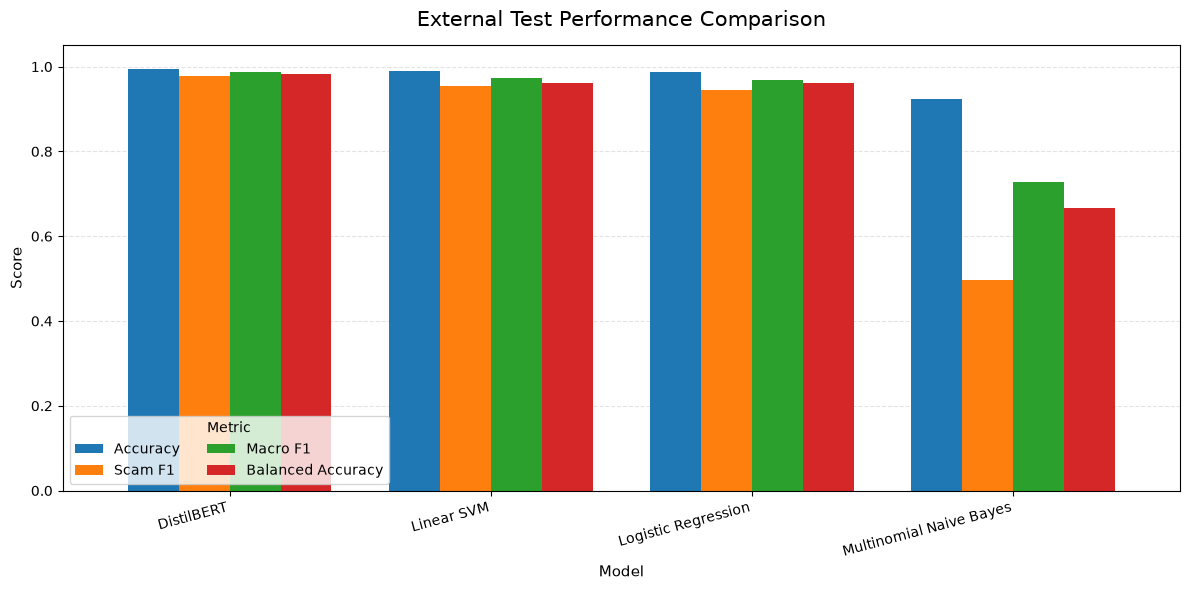

Saved PNG and PDF to: d:\Programs and Codes\financial-scam-analysis\outputs\external_evaluation_traditional_ml\results\figures


,Accuracy,Scam F1,Macro F1,Balanced Accuracy
DistilBERT,0.9953,0.9789,0.9881,0.9830
Linear SVM,0.9899,0.9539,0.9741,0.9623
Logistic Regression,0.9879,0.9453,0.9692,0.9612
Multinomial Naive Bayes,0.9241,0.4976,0.7283,0.6663


In [30]:
# 23. Overall external performance comparison

import matplotlib.pyplot as plt
import pandas as pd

# Select expanded external test results
expanded_rows = external_metrics_df[
    external_metrics_df["Dataset"] == "Expanded"
].copy()

# Use the exact model labels from your DataFrame
model_order = [
    "DistilBERT",
    "Linear SVM",
    "Logistic Regression",
    "Multinomial Naive Bayes"
]

traditional_metrics = expanded_rows.set_index("Model")

# Build comparison table
performance_plot_df = pd.DataFrame(
    {
        "Accuracy": {
            "DistilBERT": 0.995302,
            "Linear SVM": traditional_metrics.loc["Linear SVM", "Accuracy"],
            "Logistic Regression": traditional_metrics.loc["Logistic Regression", "Accuracy"],
            "Multinomial Naive Bayes": traditional_metrics.loc["Multinomial Naive Bayes", "Accuracy"]
        },
        "Scam F1": {
            "DistilBERT": 0.9789,
            "Linear SVM": traditional_metrics.loc["Linear SVM", "Scam F1"],
            "Logistic Regression": traditional_metrics.loc["Logistic Regression", "Scam F1"],
            "Multinomial Naive Bayes": traditional_metrics.loc["Multinomial Naive Bayes", "Scam F1"]
        },
        "Macro F1": {
            "DistilBERT": 0.9881,
            "Linear SVM": traditional_metrics.loc["Linear SVM", "Macro F1"],
            "Logistic Regression": traditional_metrics.loc["Logistic Regression", "Macro F1"],
            "Multinomial Naive Bayes": traditional_metrics.loc["Multinomial Naive Bayes", "Macro F1"]
        },
        "Balanced Accuracy": {
            "DistilBERT": 0.9830,
            "Linear SVM": traditional_metrics.loc["Linear SVM", "Balanced Accuracy"],
            "Logistic Regression": traditional_metrics.loc["Logistic Regression", "Balanced Accuracy"],
            "Multinomial Naive Bayes": traditional_metrics.loc["Multinomial Naive Bayes", "Balanced Accuracy"]
        }
    }
).loc[model_order]

# Plot
ax = performance_plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.78,
    ylim=(0, 1.05)
)

ax.set_title("External Test Performance Comparison", fontsize=15, pad=14)
ax.set_xlabel("Model", fontsize=11)
ax.set_ylabel("Score", fontsize=11)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
ax.legend(title="Metric", loc="lower left", ncol=2)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()

FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(FIGURES_DIR / "01_overall_performance_comparison.png",
            dpi=300, bbox_inches="tight")
plt.savefig(FIGURES_DIR / "01_overall_performance_comparison.pdf",
            bbox_inches="tight")

plt.show()

print("Saved PNG and PDF to:", FIGURES_DIR)
display(performance_plot_df.round(4))

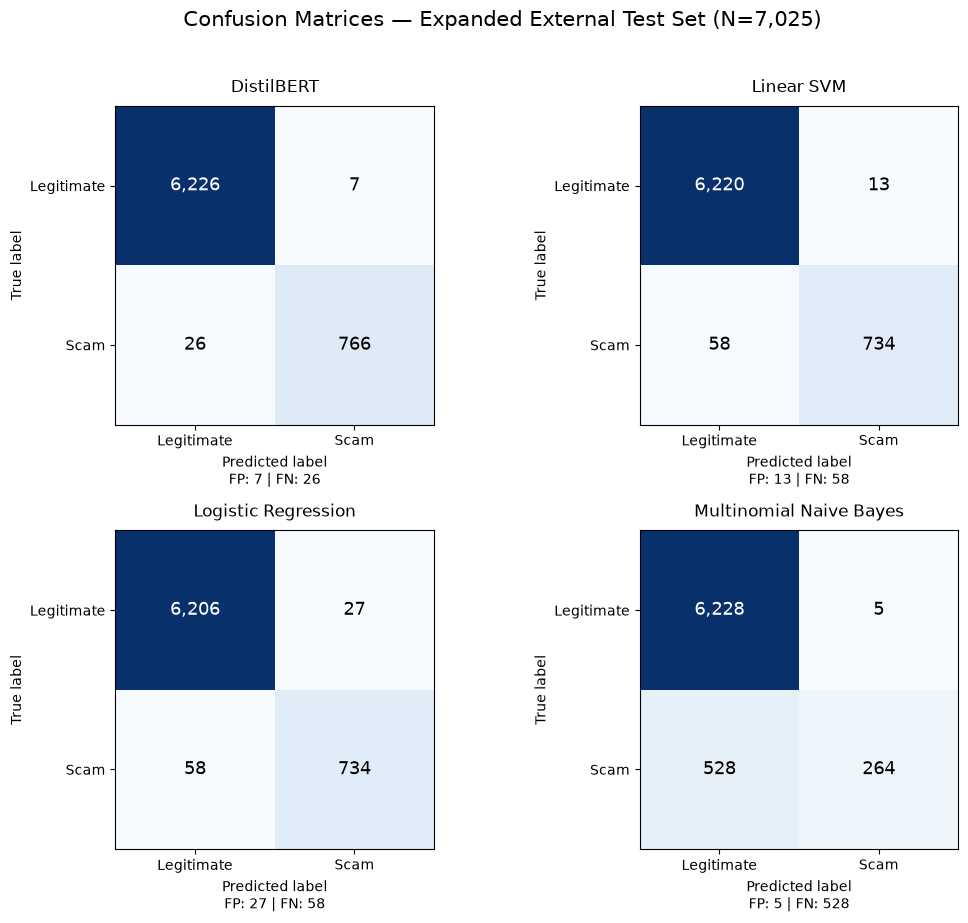

Saved confusion matrix comparison (PNG and PDF).


In [31]:
# 24. Confusion matrix comparison across all four models

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

model_predictions = {
    "DistilBERT": expanded_comparison["distilbert_pred"].to_numpy(),
    "Linear SVM": expanded_comparison["svm_pred"].to_numpy(),
    "Logistic Regression": expanded_comparison["lr_pred"].to_numpy(),
    "Multinomial Naive Bayes": expanded_comparison["nb_pred"].to_numpy()
}

y_true = expanded_comparison["label"].to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for ax, (model_name, predictions) in zip(axes, model_predictions.items()):
    cm = confusion_matrix(y_true, predictions, labels=[0, 1])

    ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(model_name, fontsize=12, pad=10)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Legitimate", "Scam"])
    ax.set_yticklabels(["Legitimate", "Scam"])

    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

    threshold = cm.max() / 2

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center",
                va="center",
                fontsize=13,
                color="white" if cm[i, j] > threshold else "black"
            )

    tn, fp, fn, tp = cm.ravel()
    ax.set_xlabel(f"Predicted label\nFP: {fp:,} | FN: {fn:,}")

fig.suptitle(
    "Confusion Matrices — Expanded External Test Set (N=7,025)",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "02_confusion_matrix_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES_DIR / "02_confusion_matrix_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved confusion matrix comparison (PNG and PDF).")

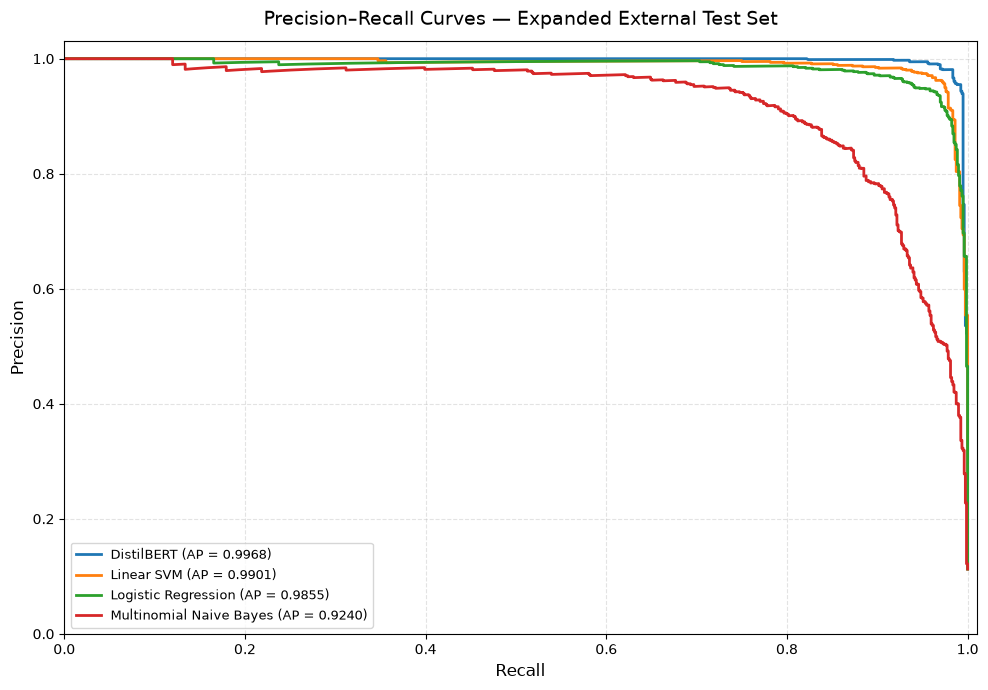

Average Precision (AP) scores:


,Model,Average Precision
0,DistilBERT,0.9968
1,Linear SVM,0.9901
2,Logistic Regression,0.9855
3,Multinomial Naive Bayes,0.9240



Saved PNG and PDF.


In [32]:
# 25. Precision-Recall curves across all four models

import matplotlib.pyplot as plt
import pandas as pd
import joblib

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Load original traditional ML artifacts
vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer.joblib")
lr_model = joblib.load(MODEL_DIR / "logistic_regression.joblib")
nb_model = joblib.load(MODEL_DIR / "multinomial_nb.joblib")
svm_model = joblib.load(MODEL_DIR / "linear_svm.joblib")

# Transform using the original training-fitted vectorizer
X_pr = vectorizer.transform(expanded_df["normalized_text"])
y_pr = expanded_df["label"].to_numpy()

# Traditional model scores
lr_scores = lr_model.predict_proba(X_pr)[:, 1]
nb_scores = nb_model.predict_proba(X_pr)[:, 1]
svm_scores = svm_model.decision_function(X_pr)

# Load DistilBERT prediction probabilities
distilbert_file = PROJECT_ROOT / "outputs" / "external_evaluation" / "primary_test_predictions.csv"
distilbert_df = pd.read_csv(distilbert_file)

# Align probabilities by record_id, not row position
pr_data = expanded_df[["record_id", "label"]].merge(
    distilbert_df[["record_id", "scam_probability"]],
    on="record_id",
    how="left",
    validate="one_to_one"
)

if pr_data["scam_probability"].isna().any():
    raise ValueError("Some DistilBERT probabilities could not be aligned.")

if not np.array_equal(pr_data["label"].to_numpy(), y_pr):
    raise ValueError("Label alignment mismatch.")

distilbert_scores = pr_data["scam_probability"].to_numpy()

# Prepare score collections
score_collections = {
    "DistilBERT": distilbert_scores,
    "Linear SVM": svm_scores,
    "Logistic Regression": lr_scores,
    "Multinomial Naive Bayes": nb_scores
}

# Plot PR curves
plt.figure(figsize=(10, 7))

ap_results = {}

for model_name, scores in score_collections.items():
    precision, recall, _ = precision_recall_curve(y_pr, scores)
    average_precision = average_precision_score(y_pr, scores)

    ap_results[model_name] = average_precision

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{model_name} (AP = {average_precision:.4f})"
    )

plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)
plt.title(
    "Precision–Recall Curves — Expanded External Test Set",
    fontsize=14,
    pad=12
)

plt.xlim(0, 1.01)
plt.ylim(0, 1.03)
plt.grid(linestyle="--", alpha=0.35)
plt.legend(loc="lower left", fontsize=9)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "03_precision_recall_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES_DIR / "03_precision_recall_curves.pdf",
    bbox_inches="tight"
)

plt.show()

print("Average Precision (AP) scores:")
display(
    pd.DataFrame(
        ap_results.items(),
        columns=["Model", "Average Precision"]
    ).sort_values("Average Precision", ascending=False).round(4)
)

print("\nSaved PNG and PDF.")

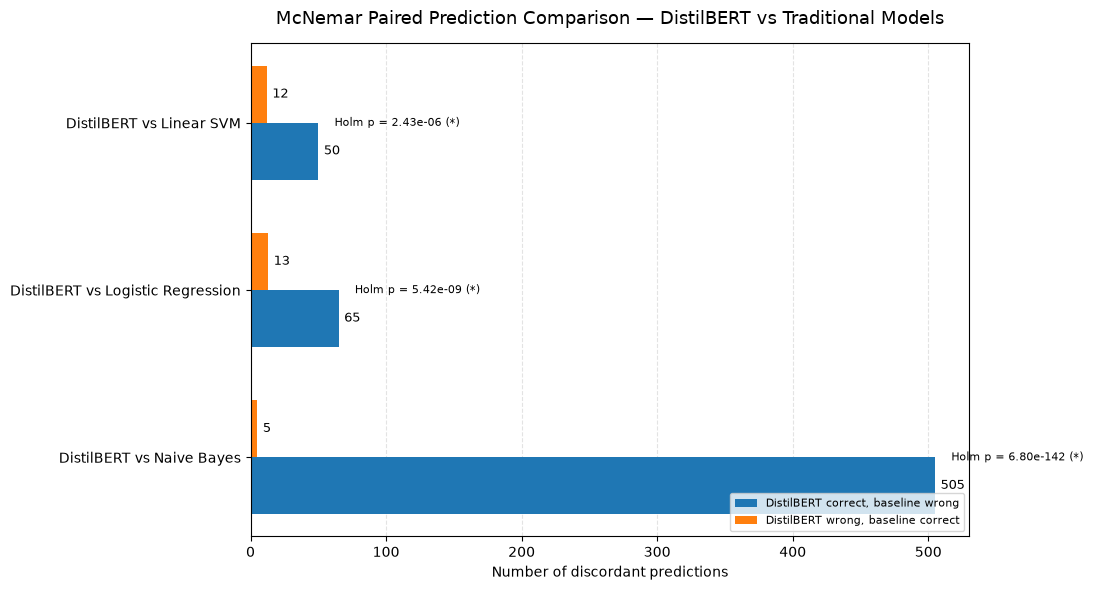

,Comparison,A_correct_B_wrong,A_wrong_B_correct,Holm_adjusted_p,Significant_after_correction
0,DistilBERT vs Naive Bayes,505,5,6.795559e-142,True
1,DistilBERT vs Logistic Regression,65,13,5.423109e-09,True
2,DistilBERT vs Linear SVM,50,12,2.428762e-06,True


Saved corrected McNemar comparison (PNG and PDF).


In [35]:
# 26. Paired McNemar discordance comparison

import matplotlib.pyplot as plt
import numpy as np

# Select DistilBERT comparisons only
plot_df = mcnemar_df[
    mcnemar_df["Comparison"].str.startswith("DistilBERT vs")
].copy()

if len(plot_df) != 3:
    raise ValueError("Expected three DistilBERT comparisons.")

# Shorten labels for readability
plot_df["Comparison"] = plot_df["Comparison"].replace({
    "DistilBERT vs Linear SVM": "DistilBERT vs Linear SVM",
    "DistilBERT vs Logistic Regression": "DistilBERT vs Logistic Regression",
    "DistilBERT vs Naive Bayes": "DistilBERT vs Naive Bayes"
})

plot_df = plot_df.iloc[::-1].reset_index(drop=True)

y = np.arange(len(plot_df))
bar_height = 0.34

fig, ax = plt.subplots(figsize=(11, 6))

bars_a = ax.barh(
    y - bar_height / 2,
    plot_df["A_correct_B_wrong"],
    height=bar_height,
    label="DistilBERT correct, baseline wrong"
)

bars_b = ax.barh(
    y + bar_height / 2,
    plot_df["A_wrong_B_correct"],
    height=bar_height,
    label="DistilBERT wrong, baseline correct"
)

ax.bar_label(bars_a, padding=4, fontsize=9)
ax.bar_label(bars_b, padding=4, fontsize=9)

# Add adjusted p-values and significance markers
for i, row in plot_df.iterrows():
    significance = "*" if row["Significant_after_correction"] else "ns"

    ax.text(
        max(row["A_correct_B_wrong"], row["A_wrong_B_correct"]) + 12,
        i,
        f"Holm p = {row['Holm_adjusted_p']:.2e} ({significance})",
        va="center",
        fontsize=8
    )

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Comparison"])
ax.set_xlabel("Number of discordant predictions")
ax.set_title(
    "McNemar Paired Prediction Comparison — DistilBERT vs Traditional Models",
    fontsize=13,
    pad=14
)

ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "04_mcnemar_discordance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES_DIR / "04_mcnemar_discordance_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

display(
    plot_df[
        [
            "Comparison",
            "A_correct_B_wrong",
            "A_wrong_B_correct",
            "Holm_adjusted_p",
            "Significant_after_correction"
        ]
    ]
)

print("Saved corrected McNemar comparison (PNG and PDF).")

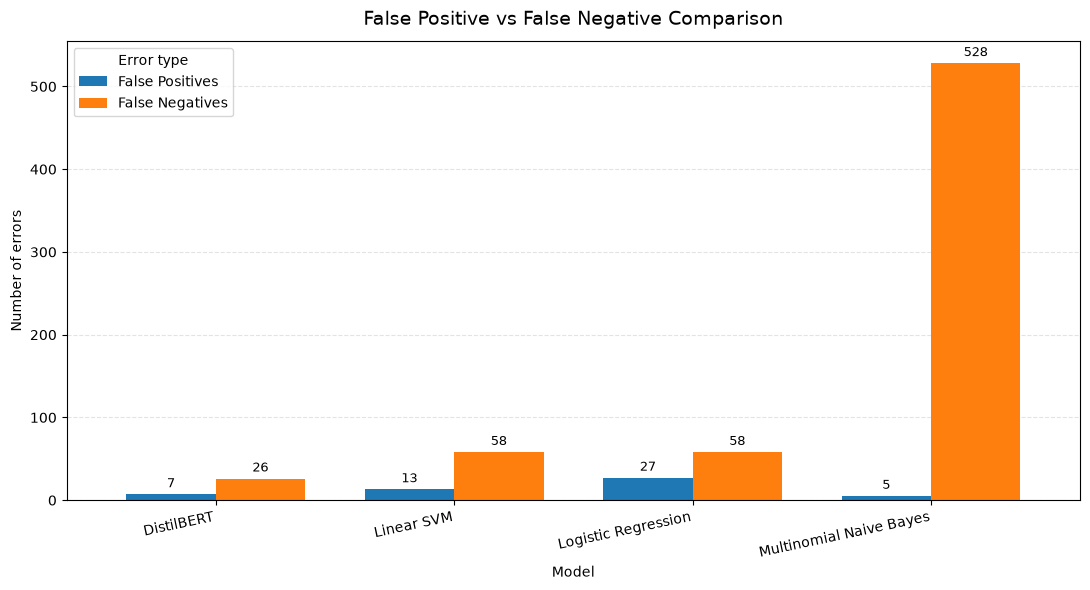

,False Positives,False Negatives
Model,,
DistilBERT,7,26
Linear SVM,13,58
Logistic Regression,27,58
Multinomial Naive Bayes,5,528


Saved error distribution plots (PNG and PDF).


In [36]:
# 27. False Positive and False Negative comparison

import matplotlib.pyplot as plt
import pandas as pd

error_data = []

for model_name, predictions in model_predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    error_data.append({
        "Model": model_name,
        "False Positives": fp,
        "False Negatives": fn
    })

error_df = pd.DataFrame(error_data).set_index("Model")

# Plot
ax = error_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title(
    "False Positive vs False Negative Comparison",
    fontsize=14,
    pad=12
)
ax.set_xlabel("Model")
ax.set_ylabel("Number of errors")
ax.set_xticklabels(ax.get_xticklabels(), rotation=12, ha="right")
ax.legend(title="Error type")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_false_positive_negative_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES_DIR / "05_false_positive_negative_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

display(error_df)
print("Saved error distribution plots (PNG and PDF).")

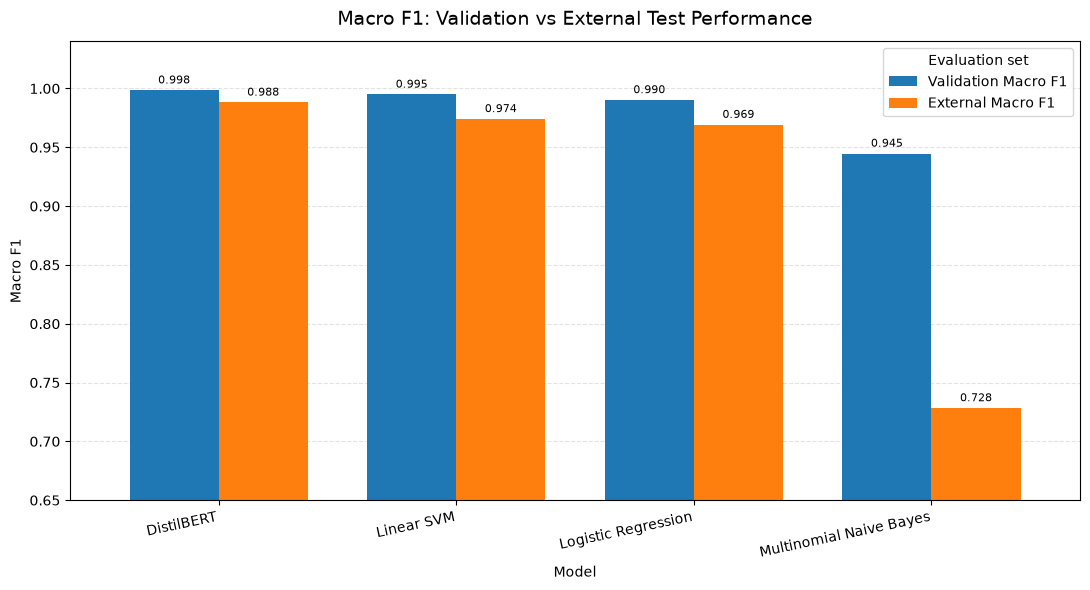

Generalization comparison:


,Validation Macro F1,External Macro F1,Macro F1 Drop
Model,,,
DistilBERT,0.9985,0.9881,0.0104
Linear SVM,0.9949,0.9741,0.0208
Logistic Regression,0.9902,0.9692,0.0210
Multinomial Naive Bayes,0.9447,0.7283,0.2164


Saved validation-to-external comparison (PNG and PDF).


In [37]:
# 28. Validation-to-external generalization comparison

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

generalization_df = pd.DataFrame({
    "Model": [
        "DistilBERT",
        "Linear SVM",
        "Logistic Regression",
        "Multinomial Naive Bayes"
    ],
    "Validation Macro F1": [
        0.9984578624,
        0.9949,
        0.9902,
        0.9447
    ],
    "External Macro F1": [
        0.9881,
        0.9741,
        0.9692,
        0.7283
    ]
}).set_index("Model")

ax = generalization_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title(
    "Macro F1: Validation vs External Test Performance",
    fontsize=14,
    pad=12
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro F1")
ax.set_ylim(0.65, 1.04)
ax.set_xticklabels(ax.get_xticklabels(), rotation=12, ha="right")
ax.legend(title="Evaluation set")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=8)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_validation_external_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES_DIR / "06_validation_external_macro_f1.pdf",
    bbox_inches="tight"
)

plt.show()

# Calculate generalization gap
generalization_df["Macro F1 Drop"] = (
    generalization_df["Validation Macro F1"]
    - generalization_df["External Macro F1"]
)

print("Generalization comparison:")
display(generalization_df.round(4))

print("Saved validation-to-external comparison (PNG and PDF).")

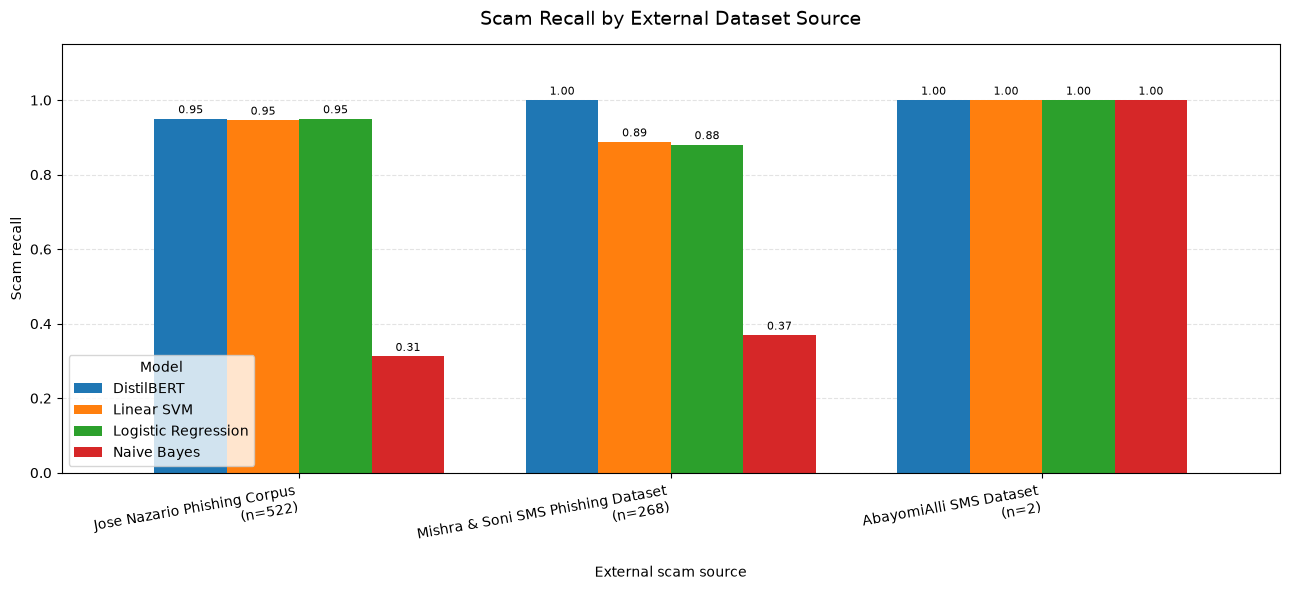

Model,DistilBERT,Linear SVM,Logistic Regression,Naive Bayes
Source,,,,
Jose Nazario Phishing Corpus,0.9502,0.9464,0.9502,0.3123
Mishra & Soni SMS Phishing Dataset,1.0000,0.8881,0.8806,0.3694
AbayomiAlli SMS Dataset,1.0000,1.0000,1.0000,1.0000



Source sample counts:


,Total scams
Source,
Jose Nazario Phishing Corpus,522
Mishra & Soni SMS Phishing Dataset,268
AbayomiAlli SMS Dataset,2


Saved per-source recall plots (PNG and PDF).


In [39]:
# 29. Per-source scam recall comparison

source_order = [
    "Jose Nazario Phishing Corpus",
    "Mishra & Soni SMS Phishing Dataset",
    "AbayomiAlli SMS Dataset"
]

model_order = [
    "DistilBERT",
    "Linear SVM",
    "Logistic Regression",
    "Naive Bayes"
]

pivot_recall = source_plot_df.pivot(
    index="Source",
    columns="Model",
    values="Recall"
).reindex(source_order)[model_order]

sample_counts = (
    source_plot_df.groupby("Source")["Total scams"]
    .first()
    .reindex(source_order)
)

ax = pivot_recall.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.78
)

ax.set_title(
    "Scam Recall by External Dataset Source",
    fontsize=14,
    pad=14
)
ax.set_xlabel("External scam source")
ax.set_ylabel("Scam recall")
ax.set_ylim(0, 1.15)
ax.set_xticklabels(ax.get_xticklabels(), rotation=10, ha="right")
ax.legend(title="Model", loc="lower left")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=2,
        fontsize=8
    )

# Display sample count beneath each source label
ax.set_xticklabels([
    f"{source}\n(n={sample_counts[source]})"
    for source in source_order
], rotation=10, ha="right")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "07_per_source_scam_recall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    FIGURES_DIR / "07_per_source_scam_recall.pdf",
    bbox_inches="tight"
)

plt.show()

display(pivot_recall.round(4))
print("\nSource sample counts:")
display(sample_counts.to_frame("Total scams"))

print("Saved per-source recall plots (PNG and PDF).")

In [42]:
# 30. Final consolidated model comparison

# Validation Macro F1
validation_macro_f1 = {
    "DistilBERT": 0.9984578624,
    "Linear SVM": 0.9949,
    "Logistic Regression": 0.9902,
    "Multinomial Naive Bayes": 0.9447
}

# External metrics: traditional models only
external_summary = external_metrics_df[
    external_metrics_df["Dataset"] == "Expanded"
].set_index("Model")

# Error counts
error_summary = error_df.copy()

# Average Precision
ap_summary = {
    "DistilBERT": ap_results["DistilBERT"],
    "Linear SVM": ap_results["Linear SVM"],
    "Logistic Regression": ap_results["Logistic Regression"],
    "Multinomial Naive Bayes": ap_results["Multinomial Naive Bayes"]
}

# DistilBERT metrics from Notebook 09
distilbert_metrics = {
    "Accuracy": 0.995302,
    "Precision": 0.9909,
    "Recall": 0.9672,
    "Scam F1": 0.9789,
    "Macro F1": 0.9881,
    "Balanced Accuracy": 0.9830
}

model_order = [
    "DistilBERT",
    "Linear SVM",
    "Logistic Regression",
    "Multinomial Naive Bayes"
]

summary_records = []

for model_name in model_order:

    if model_name == "DistilBERT":
        metrics = distilbert_metrics
    else:
        row = external_summary.loc[model_name]
        metrics = row

    error_name = model_name

    summary_records.append({
        "Model": model_name,
        "Validation Macro F1": validation_macro_f1[model_name],
        "External Accuracy": metrics["Accuracy"],
        "Scam Precision": metrics["Precision"],
        "Scam Recall": metrics["Recall"],
        "Scam F1": metrics["Scam F1"],
        "External Macro F1": metrics["Macro F1"],
        "Balanced Accuracy": metrics["Balanced Accuracy"],
        "Average Precision": ap_summary[model_name],
        "False Positives": error_summary.loc[error_name, "False Positives"],
        "False Negatives": error_summary.loc[error_name, "False Negatives"]
    })

final_summary_df = pd.DataFrame(summary_records).set_index("Model")

# Display final results
display(final_summary_df.round(4))

# Export
final_summary_df.to_csv(
    RESULTS_DIR / "final_model_comparison_summary.csv"
)

print("\nFinal comparison table saved:")
print(RESULTS_DIR / "final_model_comparison_summary.csv")

,Validation Macro F1,External Accuracy,Scam Precision,Scam Recall,Scam F1,External Macro F1,Balanced Accuracy,Average Precision,False Positives,False Negatives
Model,,,,,,,,,,
DistilBERT,0.9985,0.9953,0.9909,0.9672,0.9789,0.9881,0.9830,0.9968,7,26
Linear SVM,0.9949,0.9899,0.9826,0.9268,0.9539,0.9741,0.9623,0.9901,13,58
Logistic Regression,0.9902,0.9879,0.9645,0.9268,0.9453,0.9692,0.9612,0.9855,27,58
Multinomial Naive Bayes,0.9447,0.9241,0.9814,0.3333,0.4976,0.7283,0.6663,0.9240,5,528



Final comparison table saved:
d:\Programs and Codes\financial-scam-analysis\outputs\external_evaluation_traditional_ml\results\final_model_comparison_summary.csv
